## 1. Importing Necessary Libraries

In [57]:
import numpy as  np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score)

from statsmodels.tsa.arima.model import ARIMA

nltk.download("stopwords")
nltk.download("wordnet")

sns.set_theme(style='whitegrid')
os.makedirs('output',exist_ok = True)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\chris\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\chris\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## 2. Dataset Overview

In [59]:
# loads the dataset
df = pd.read_csv('chatgpt_reviews.csv')

print(df.shape)
print(df.columns)
df.head()

(1033487, 8)
Index(['reviewId', 'userName', 'content', 'score', 'thumbsUpCount',
       'reviewCreatedVersion', 'at', 'appVersion'],
      dtype='object')


,reviewId,userName,content,score,thumbsUpCount,reviewCreatedVersion,at,appVersion
0,035d9af4-769a-48d0-9883-d7703c0c77e6,Isha Isha soni,good apps,5,0,1.2026.118,2026-05-13 09:46:43,1.2026.118
1,652daaa8-4662-4c61-af2e-d352195acae0,Ani Kelly,Brilliant,5,0,1.2026.125,2026-05-13 09:46:35,1.2026.125
2,b4a541ba-63f1-499f-b768-15ad4a34b520,Saiful Islam,"অনেক হেল্প ফুল, অনেক উপকারী মানুষের জন্য অনেক ...",5,0,1.2026.125,2026-05-13 09:46:24,1.2026.125
3,e486bd86-e8cc-4180-8f8e-cd42dceadc17,Gowtham Gowthu,normal,3,0,1.2026.125,2026-05-13 09:46:00,1.2026.125
4,11cb1534-315a-4574-9084-2b442e9893ef,vikash kumar,This app is very helpful for students. It can ...,5,0,1.2026.118,2026-05-13 09:45:59,1.2026.118


## 3. Data Preprocessing

In [61]:
df = df[["content", "score", "at"]].copy()                 # keeps only necessary columns

df.columns = ['review', 'rating', 'date']                  #  Renaming columns 

df = df.dropna(subset = ['review', 'rating', 'date'])      # removes rows where review, rating, or date is missing

print('Shape after dropping nulls:',df.shape)
df.head()

Shape after dropping nulls: (1033471, 3)


,review,rating,date
0,good apps,5,2026-05-13 09:46:43
1,Brilliant,5,2026-05-13 09:46:35
2,"অনেক হেল্প ফুল, অনেক উপকারী মানুষের জন্য অনেক ...",5,2026-05-13 09:46:24
3,normal,3,2026-05-13 09:46:00
4,This app is very helpful for students. It can ...,5,2026-05-13 09:45:59


In [63]:
#  Since the dataset is very large, sampling makes it process faster
df = df.sample(50000, random_state=42).reset_index(drop=True)

print("Sample size:", df.shape)

Sample size: (50000, 3)


In [65]:
# date parsing
df['date'] = pd.to_datetime(df['date'],errors = 'coerce')   # converts date column into universal datetime format 

df = df.dropna(subset=['date'])                             # Remove rows with invalid dates

df['month'] = df['date'].dt.to_period('M').astype(str)      # Create month column for monthly trend analysis

print('Date range:',df['month'].min(), 'to', df['month'].max())

Date range: 2023-07 to 2026-05


 ### Text cleaning

In [67]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()                    # converts words to base form

def cleans_text(text):                              # function to clean review text
    text = str(text).lower()
    text = re.sub(r'http\S+',' ',text)
    text = re.sub(r'[^a-z\s]',' ',text)
    text = re.sub(r'\s+',' ',text).strip()

    tokens = text.split()                           # Split text into words
    
    tokens = [
        lemmatizer.lemmatize(word)                  
        for word in tokens
        if word  not in stop_words  and len(word) > 1
    ]

    return ' '.join(tokens)

df['clean_review'] = df['review'].apply(cleans_text)                # apply cleaning to all reviews
df['word_count'] = df['clean_review'].str.split().apply(len)        # wordcount after cleaning

df = df[df["word_count"] > 0].copy()                                # removes reviews that is empty after cleaning

print(df.shape)
df.head()


(47453, 6)


,review,rating,date,month,clean_review,word_count
0,very nice,5,2026-04-03 09:35:48,2026-04,nice,1
1,Thank you for assisting my paper with English ...,5,2023-07-25 19:13:34,2023-07,thank assisting paper english grammar check cr...,16
2,very good,5,2025-05-24 07:02:55,2025-05,good,1
3,nice,4,2025-06-20 04:30:51,2025-06,nice,1
4,"Very appropriate and authentic, easy to use.",5,2025-04-06 07:48:01,2025-04,appropriate authentic easy use,4


###  Create Sentiment Labels

In [77]:
# converts star ratings into sentiment categories
def rating_to_sentiment(rating):
    if  rating <=  2:
        return 'negative'
    elif rating == 3:
        return 'neutral'
    else:
        return 'positive'

df['sentiment'] = df['rating'].apply(rating_to_sentiment)

df['sentiment'].value_counts()

sentiment
positive    41515
negative     4015
neutral      1923
Name: count, dtype: int64

## 4. Exploratory Data Analysis

### Plot rating distribution

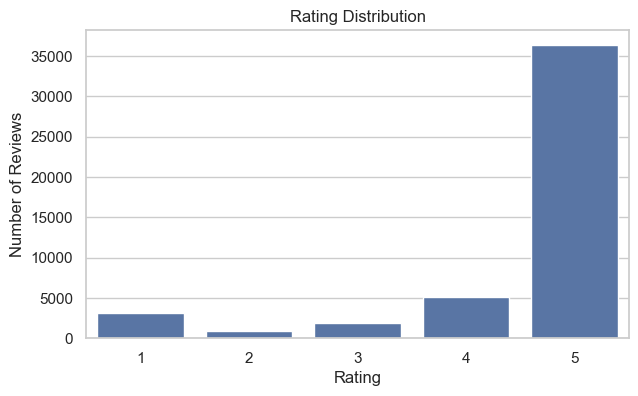

In [94]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="rating")
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

### Plot sentiment distribution

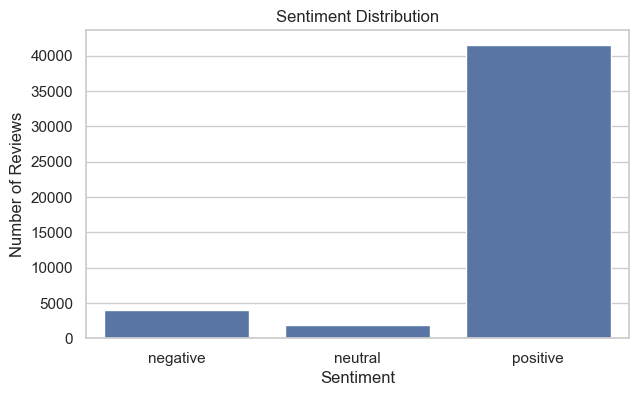

In [92]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="sentiment", order=["negative", "neutral", "positive"])
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

### Top terms by sentiment

In [102]:
def get_top_terms(dataframe, sentiment_label, n=15):                                # identify important words in each sentiment group
    
    subset = dataframe[dataframe["sentiment"] == sentiment_label]["clean_review"]   # Select reviews belonging to one sentiment category

    vectorizer = TfidfVectorizer(                                                   # Convert text into TF-IDF features
        max_features=3000,
        ngram_range=(1, 2)
    )

    X_subset = vectorizer.fit_transform(subset)

    scores = np.asarray(X_subset.mean(axis=0)).ravel()                              # Calculate average TF-IDF score for each term

    terms = np.array(vectorizer.get_feature_names_out()) 


    top_idx = scores.argsort()[::-1][:n]                                            # Select top terms

    return pd.DataFrame({
        "sentiment": sentiment_label,
        "term": terms[top_idx],
        "score": scores[top_idx]
    })
top_negative = get_top_terms(df, "negative", n=15)                                  # Get top terms for each sentiment
top_neutral = get_top_terms(df, "neutral", n=15)
top_positive = get_top_terms(df, "positive", n=15)

top_terms_df = pd.concat(
    [top_negative, top_neutral, top_positive],
    ignore_index=True
)

top_terms_df.to_csv("output/top_terms_by_sentiment.csv", index=False)

top_terms_df

,sentiment,term,score
0,negative,good,0.100697
1,negative,nice,0.045695
2,negative,app,0.041270
3,negative,bad,0.032875
4,negative,working,0.016997
5,negative,slow,0.015061
6,negative,best,0.015053
7,negative,time,0.014040
8,negative,work,0.012298
9,negative,image,0.012075


In [83]:
# checking reviews and the given ratings
df[
    (df["sentiment"] == "negative") &
    (df["clean_review"].str.contains("good", na=False))
][["review", "rating"]].head(10)

,review,rating
269,very good 👍👍😊,1
279,Good view,2
339,good,2
491,good for douts,2
561,good,1
647,it is good to use in collage Uses,2
685,the app was good but the AI gave me too much w...,1
690,good,1
827,good,2
873,"It's OK, but not as good as being able to buy ...",1


### Top TF-IDF negative and positive terms

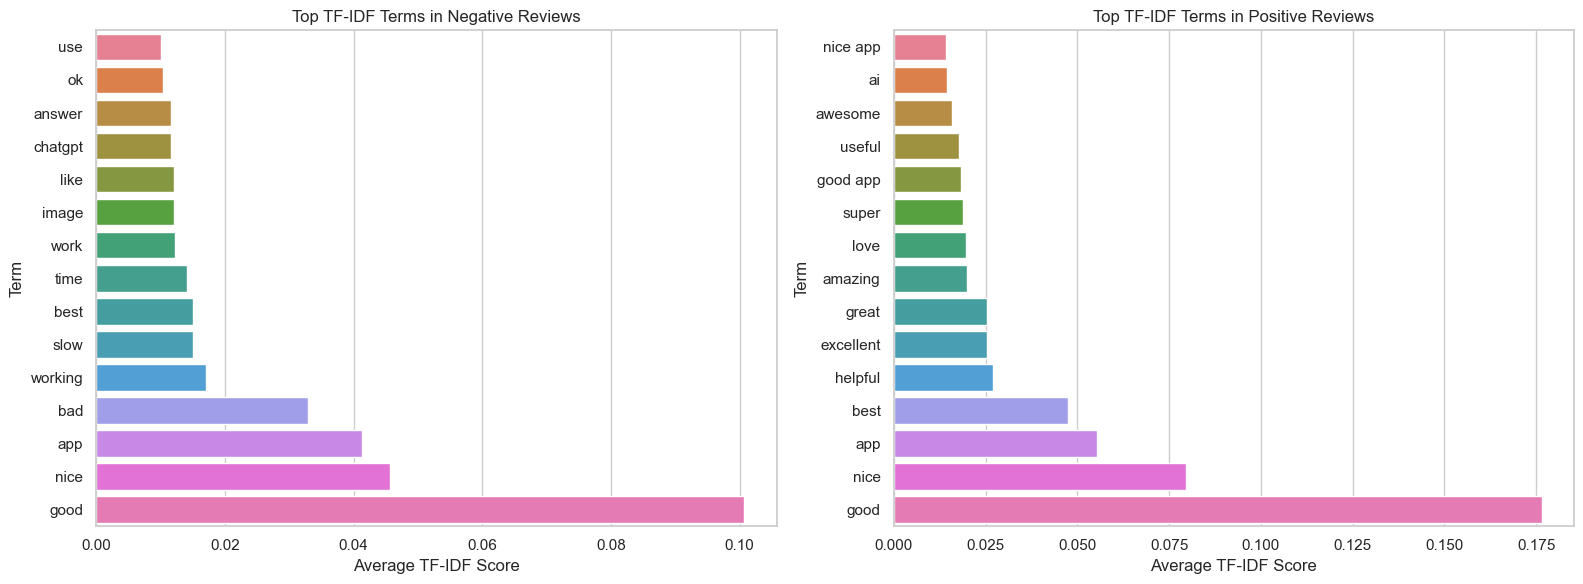

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# Negative Reviews
sns.barplot(
    data=top_negative.sort_values("score", ascending=True),
    x="score",
    y="term",
    hue="term",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Top TF-IDF Terms in Negative Reviews")
axes[0].set_xlabel("Average TF-IDF Score")
axes[0].set_ylabel("Term")

# Positive Reviews
sns.barplot(
    data=top_positive.sort_values("score", ascending=True),
    x="score",
    y="term",
    hue="term",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Top TF-IDF Terms in Positive Reviews")
axes[1].set_xlabel("Average TF-IDF Score")
axes[1].set_ylabel("Term")

plt.tight_layout()
plt.show()

## 5. Balancing Data for Model Training

In [111]:
# print imbalanced data
print(df["sentiment"].value_counts())

print(df["sentiment"].value_counts(normalize=True) * 100)

sentiment
positive    41515
negative     4015
neutral      1923
Name: count, dtype: int64
sentiment
positive    87.486566
negative     8.461004
neutral      4.052431
Name: proportion, dtype: float64


In [115]:
# balancing the dataset
min_class_size = df["sentiment"].value_counts().min()

df_ml = (
    df.groupby("sentiment", group_keys=False)
      .apply(lambda x: x.sample(min_class_size, random_state=42))
      .reset_index(drop=True)
)
print("Balanced dataset:")
print(df_ml["sentiment"].value_counts())

Balanced dataset:
sentiment
negative    1923
neutral     1923
positive    1923
Name: count, dtype: int64


## 7. Train-Test Split

In [118]:
X = df_ml["clean_review"]
y = df_ml["sentiment"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training labels:")
print(y_train.value_counts())

print("Testing labels:")
print(y_test.value_counts())

Training labels:
sentiment
negative    1539
positive    1538
neutral     1538
Name: count, dtype: int64
Testing labels:
sentiment
positive    385
neutral     385
negative    384
Name: count, dtype: int64


## 6. Feature Engineering

In [120]:
# TF-IDF vectorizer converts texts into numerical features
tfidf = TfidfVectorizer(
    max_features=5000,       
    ngram_range=(1,2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (4615, 5000)
Testing matrix shape: (1154, 5000)


## 8. Model Training

In [124]:
# Logistic Regression classifier
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_tfidf, y_train)
y_pred = model.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.5424610051993067

Classification Report:

              precision    recall  f1-score   support

    negative       0.61      0.63      0.62       384
     neutral       0.44      0.46      0.45       385
    positive       0.59      0.53      0.56       385

    accuracy                           0.54      1154
   macro avg       0.55      0.54      0.54      1154
weighted avg       0.55      0.54      0.54      1154



## 9. Confusion Matrix

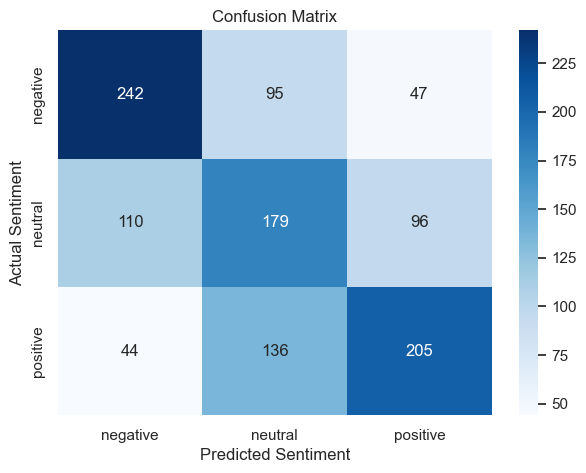

In [127]:
labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

## 10. Monthly Sentiment Trend

In [130]:
# Count reviews by month and sentiment
monthly_sentiment = (
    df.groupby(["month", "sentiment"])
      .size()
      .reset_index(name="count")
)

monthly_total = df.groupby("month").size().reset_index(name="total")

monthly_sentiment = monthly_sentiment.merge(monthly_total, on="month")

monthly_sentiment["share"] = monthly_sentiment["count"] / monthly_sentiment["total"]

monthly_sentiment.head()

,month,sentiment,count,total,share
0,2023-07,negative,44,408,0.107843
1,2023-07,neutral,19,408,0.046569
2,2023-07,positive,345,408,0.845588
3,2023-08,negative,39,299,0.130435
4,2023-08,neutral,15,299,0.050167


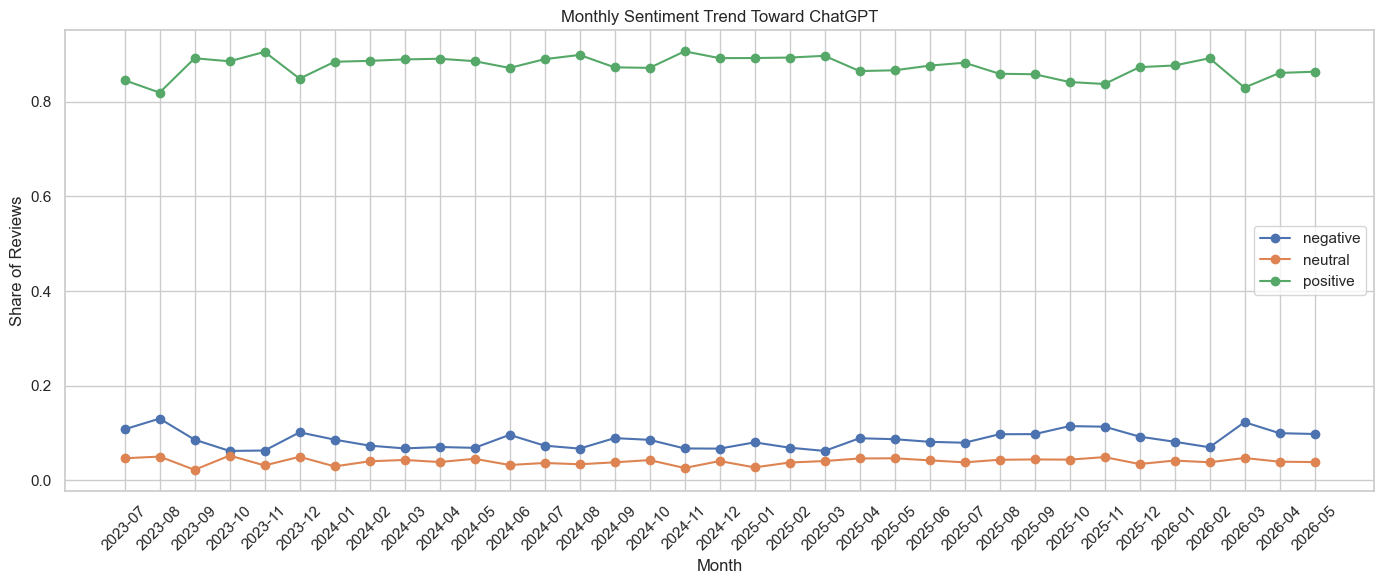

In [134]:
# Plot monthly sentiment trend
plt.figure(figsize=(14, 6))

for sentiment in ["negative", "neutral", "positive"]:
    temp = monthly_sentiment[monthly_sentiment["sentiment"] == sentiment]
    plt.plot(temp["month"], temp["share"], marker="o", label=sentiment)

plt.title("Monthly Sentiment Trend Toward ChatGPT")
plt.xlabel("Month")
plt.ylabel("Share of Reviews")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 11. Preparing Negative Sentiment For Forecasting

In [137]:
# Select only negative sentiment trend
negative_trend = monthly_sentiment[
    monthly_sentiment["sentiment"] == "negative"
][["month", "share"]].copy()

negative_trend["month"] = pd.to_datetime(negative_trend["month"])
negative_trend = negative_trend.sort_values("month")

negative_trend.set_index("month", inplace=True)

negative_trend.head()

,share
month,
2023-07-01,0.107843
2023-08-01,0.130435
2023-09-01,0.085873
2023-10-01,0.062092
2023-11-01,0.062954


## 12. Forecasting Negative Sentiment using ARIMA

In [141]:
# ARIMA forecasts future negative sentiment share
model_arima = ARIMA(
    negative_trend["share"],
    order=(1, 1, 1)
)

arima_result = model_arima.fit()                                       # Train ARIMA model

forecast = arima_result.forecast(steps=6)                              # Forecast next 6 months

 
forecast_dates = pd.date_range(                                        # Create future month dates
    start=negative_trend.index[-1] + pd.DateOffset(months=1),
    periods=6,
    freq="MS"
)

forecast_df = pd.DataFrame({
    "month": forecast_dates,
    "forecast_negative_share": forecast.values
})

forecast_df

C:\Users\chris\anaconda3\envs\nlp_env\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\chris\anaconda3\envs\nlp_env\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\chris\anaconda3\envs\nlp_env\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,month,forecast_negative_share
0,2026-06-01,0.091454
1,2026-07-01,0.088619
2,2026-08-01,0.087374
3,2026-09-01,0.086827
4,2026-10-01,0.086587
5,2026-11-01,0.086482


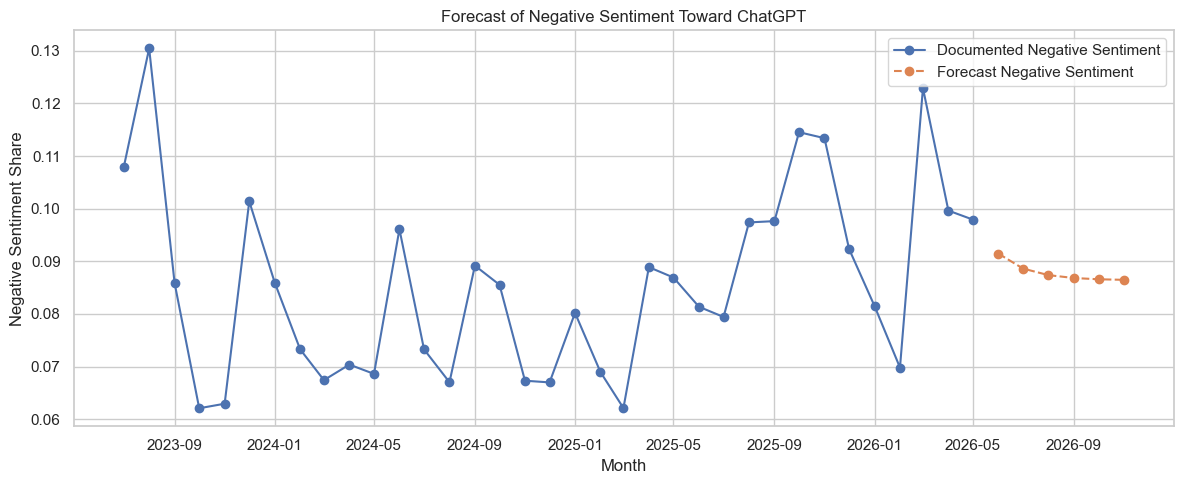

In [160]:
# plot negative sentiment for documentedl v/s forecasting
plt.figure(figsize=(12, 5))

plt.plot(                                                          #
    negative_trend.index,
    negative_trend["share"],
    marker="o",
    label="Documented Negative Sentiment"
)

plt.plot(                                                                 
    forecast_df["month"],
    forecast_df["forecast_negative_share"],
    marker="o",
    linestyle="--",
    label="Forecast Negative Sentiment"
)

plt.title("Forecast of Negative Sentiment Toward ChatGPT")
plt.xlabel("Month")
plt.ylabel("Negative Sentiment Share")
plt.legend()
plt.tight_layout()
plt.show()